# Quantum computing from scratch

Welcome! This tutorial is for you if you have heard about quantum computing but have never written a line of quantum code, or if words like *qubit*, *superposition* and *entanglement* still sound more like science fiction than computer science. You don't need any background in physics. All you need is some basic Python and a bit of high-school math (squares, square roots and probabilities).

Instead of starting with pages of linear algebra, we will learn every concept by **running code**. Each idea is introduced with a small Qrisp experiment that you can modify and re-run yourself. Here is the plan:

1. **From bits to qubits:** what a qubit is and how we manipulate it with gates.
2. **Superposition:** what it means for a qubit to be "0 and 1 at the same time", how measurement works, and why quantum randomness is *not* the same as flipping a coin.
3. **Many qubits:** why the power (and the difficulty) of quantum computing grows exponentially.
4. **Entanglement:** Bell states, spooky correlations and quantum teleportation.
5. **The Qrisp way:** how to think in terms of numbers and conditions instead of individual qubits.
6. **Your first quantum algorithms:** Deutsch–Jozsa, Bernstein–Vazirani and Grover's search.

Once you're done, you'll be perfectly prepared for the next tutorial, [Getting familiar with Qrisp](tutorial.ipynb).

If you haven't installed Qrisp yet, follow the [setup instructions](../setup.rst) or simply run the cell below.

In [1]:
# Uncomment the next line to install Qrisp
# !pip install qrisp

## 1. From bits to qubits

### Classical bits

Every computer you have ever used stores information in **bits**. A bit has exactly two possible values: 0 or 1. Everything your laptop does, from rendering this page to playing a video, boils down to flipping bits with simple logic operations such as NOT, AND and OR.

### Your first qubit

A quantum computer works with **qubits** (short for *quantum bits*). Just like a bit, whenever we look at a qubit we find either 0 or 1. But as you'll see shortly, *before* we look, a qubit can be in a state that has no classical counterpart.

In Qrisp, qubits live inside a [QuantumVariable](../../reference/Core/QuantumVariable.rst). Let's create one that holds a single qubit:

In [2]:
from qrisp import QuantumVariable

qubit = QuantumVariable(1, name="qubit")

The first argument is the number of qubits; the optional `name` is just a label for our convenience. A freshly created qubit always starts in the state 0. Physicists write this as $|0\rangle$ (pronounced "ket zero"). This angle-bracket notation is called *Dirac notation*. For now you can treat it as a label: $|0\rangle$ and $|1\rangle$ are the quantum versions of the bit values 0 and 1.

What happens if we print our qubit?

In [3]:
print(qubit)

{'0': 1.0}


Printing a QuantumVariable asks a simulator: *"If I measured this variable, which results could I get, and with what probability?"* The answer is a dictionary mapping each possible outcome to its probability. Here we get the outcome `'0'` with probability `1.0`, i.e. 100%. No surprises yet.

> **Note:** Qrisp ships with its own fast simulator, so everything in this tutorial runs on your own computer. At the end we'll briefly look at how to send the same code to a real quantum computer.

### Quantum gates: the X gate

To change the state of a qubit, we apply **quantum gates**. The simplest one is the **X gate**, the quantum version of the classical NOT: it turns $|0\rangle$ into $|1\rangle$ and vice versa.

In [4]:
from qrisp import x

x(qubit)
print(qubit)

{'1': 1.0}


Every operation we apply is recorded in a [QuantumSession](../../reference/Core/QuantumSession.rst), which we can access via the `.qs` attribute. Printing it shows the **quantum circuit** we have built so far:

In [5]:
print(qubit.qs)

QuantumCircuit:
---------------
         ┌───┐
qubit.0: ┤ X ├
         └───┘
Live QuantumVariables:
----------------------
QuantumVariable qubit


How to read a circuit diagram: each horizontal line is a qubit, time flows from left to right, and each box is a gate applied to that qubit. Quantum circuits are the "assembly language" of quantum computers. Qrisp lets you program at a much higher level (we'll get there in Section 5), but under the hood everything is eventually compiled into a circuit like this one.

So far, a qubit behaves exactly like a bit. Time to change that.

## 2. Superposition

### The Hadamard gate

The **Hadamard gate** (or H gate) is the gate that brings out the "quantumness" of a qubit. Let's apply it to a fresh qubit in state $|0\rangle$:

In [6]:
from qrisp import h

qubit = QuantumVariable(1)
h(qubit)
print(qubit)

{'0': 0.5, '1': 0.5}


Now the outcome is `'0'` with 50% probability and `'1'` with 50% probability. The qubit is in a **superposition** of $|0\rangle$ and $|1\rangle$.

To see what is going on *inside* the qubit, we can ask the simulator for the full quantum state, the so-called **statevector**:

In [7]:
qubit.qs.statevector()

sqrt(2)*(|0> + |1>)/2

The result reads $\frac{\sqrt{2}}{2}\left(|0\rangle + |1\rangle\right)$, which is the same as $\frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle$.

This tells us how quantum states are described in general. The state of a single qubit is a combination

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle,$$

where the numbers $\alpha$ and $\beta$ are called **amplitudes**. They connect to probabilities via the **Born rule**:

$$P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2.$$

In our case $\alpha = \beta = \frac{1}{\sqrt{2}}$, so both probabilities are $\left(\frac{1}{\sqrt{2}}\right)^2 = \frac{1}{2}$, exactly what `print` showed us. Since probabilities must add up to one, amplitudes always satisfy $|\alpha|^2 + |\beta|^2 = 1$.

Here is the crucial twist: unlike probabilities, **amplitudes can be negative** (in general, they can even be complex numbers). This seemingly small detail is the source of everything that makes quantum computing different, as we will see in a moment.

> This particular state $\frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$ shows up so often that it has its own name: $|+\rangle$ ("plus").

### Measurement: getting answers out

On a real quantum computer you can never look at the amplitudes directly. When you **measure** a qubit, you get a single result, 0 or 1, chosen at random according to the Born rule. After the measurement the superposition is gone: the qubit has "collapsed" to the value you observed.

To learn the probabilities, you therefore have to prepare the same state many times and measure it each time. Each repetition is called a **shot**. We can mimic this with the `shots` keyword of `get_measurement`. Let's measure our qubit 20 times, one shot at a time:

In [8]:
outcomes = [list(qubit.get_measurement(shots=1))[0] for _ in range(20)]
print("".join(outcomes))

00110011101011011000


A random sequence of 0s and 1s (run the cell again and you'll get a different one). With many shots, the relative frequencies approach the true probabilities:

In [9]:
qubit.get_measurement(shots=1000)

{'1': 0.514, '0': 0.486}

### Superposition is *not* just "we don't know yet"

At this point you might think: *"So the Hadamard gate is just a coin flip. The qubit is secretly 0 or 1, and we only find out which when we measure."*

Let's test this idea. If H really were a coin flip, applying it twice would be like flipping a coin twice, and the result would still be 50/50 random:

In [10]:
qubit = QuantumVariable(1)
h(qubit)
h(qubit)
print(qubit)

{'0': 1.0}


The qubit is back in state 0 **with certainty**! No coin behaves like that. To understand what happened, we need to know how the Hadamard gate acts on the amplitudes:

$$H|0\rangle = \tfrac{1}{\sqrt{2}}\left(|0\rangle + |1\rangle\right), \qquad H|1\rangle = \tfrac{1}{\sqrt{2}}\left(|0\rangle - |1\rangle\right).$$

Applying H a second time to $\frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$ means applying it to each part separately:

$$H\left(\tfrac{1}{\sqrt{2}}|0\rangle + \tfrac{1}{\sqrt{2}}|1\rangle\right) = \underbrace{\tfrac{1}{2}|0\rangle + \tfrac{1}{2}|1\rangle}_{\text{from } |0\rangle} + \underbrace{\tfrac{1}{2}|0\rangle - \tfrac{1}{2}|1\rangle}_{\text{from } |1\rangle} = |0\rangle.$$

There are two "paths" leading to the outcome $|1\rangle$, with amplitudes $+\frac{1}{2}$ and $-\frac{1}{2}$. They **cancel each other out**. The two paths leading to $|0\rangle$ add up instead. This effect is called **interference**, the same phenomenon that makes waves in water or light amplify or cancel each other. Because probabilities can never be negative, classical randomness cannot interfere. Amplitudes can.

> **Key insight:** Interference is the engine of every quantum algorithm. The art of designing quantum algorithms consists of arranging the computation so that the amplitudes of wrong answers cancel out while those of the right answers add up. Keep this in mind, it will come back in every algorithm we look at.

### Phase: the hidden half of a qubit

Let's prepare a slightly different state by applying X first and then H. Based on the formula above, this should give $\frac{1}{\sqrt{2}}(|0\rangle - |1\rangle)$, a state known as $|-\rangle$ ("minus"):

In [11]:
minus = QuantumVariable(1)
x(minus)
h(minus)
print(minus)
minus.qs.statevector()

{'0': 0.5, '1': 0.5}


sqrt(2)*(|0> - |1>)/2

When measured, $|-\rangle$ is indistinguishable from $|+\rangle$: 50% each. The only difference is the minus sign in front of $|1\rangle$, called a **relative phase**. Measurement cannot see it directly, but interference can. Watch what happens when we apply another H gate:

In [12]:
h(minus)
print(minus)

{'1': 1.0}


This time the paths to $|0\rangle$ cancel and we end up in $|1\rangle$. So $|+\rangle$ and $|-\rangle$ are genuinely different states, even though they produce identical measurement statistics.

There is a gate that changes nothing but the phase: the **Z gate** flips the sign of the $|1\rangle$ amplitude, $Z(\alpha|0\rangle + \beta|1\rangle) = \alpha|0\rangle - \beta|1\rangle$. On its own it seems useless, since it doesn't change any probabilities. But sandwiched between two H gates, the hidden sign becomes visible:

In [13]:
from qrisp import z

qubit = QuantumVariable(1)
h(qubit)  # |0> -> |+>
z(qubit)  # |+> -> |->   (invisible to measurement!)
h(qubit)  # |-> -> |1>   (interference makes it visible)
print(qubit)

{'1': 1.0}


H, then Z, then H has the same effect as an X gate. Remember this trick: **using Z to flip the sign of an amplitude, and then interference to turn that sign into a measurable result**, is exactly how the algorithms in Section 6 work.

### Any superposition you like: rotation gates

Superpositions don't have to be 50/50. The rotation gate `ry` takes an angle $\theta$ and turns $|0\rangle$ into

$$R_y(\theta)|0\rangle = \cos(\theta/2)\,|0\rangle + \sin(\theta/2)\,|1\rangle.$$

For example, $\theta = \pi/3$ gives $\sin^2(\pi/6) = 0.25$, a "biased coin" that lands on 1 a quarter of the time:

In [14]:
import numpy as np
from qrisp import ry

biased = QuantumVariable(1)
ry(np.pi / 3, biased)
print(biased)

{'0': 0.75, '1': 0.25}


Let's sweep the angle from $0$ to $2\pi$ and compare Qrisp's simulation with the formula $P(1) = \sin^2(\theta/2)$:

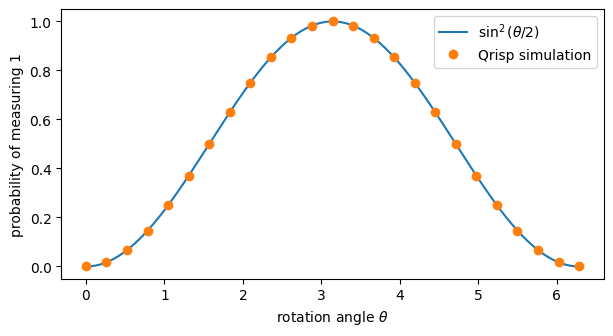

In [15]:
import matplotlib.pyplot as plt

angles = np.linspace(0, 2 * np.pi, 25)
p1 = []
for theta in angles:
    q = QuantumVariable(1)
    ry(theta, q)
    p1.append(q.get_measurement().get("1", 0))

fine = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(7, 3.5))
plt.plot(fine, np.sin(fine / 2) ** 2, label=r"$\sin^2(\theta/2)$")
plt.plot(angles, p1, "o", label="Qrisp simulation")
plt.xlabel(r"rotation angle $\theta$")
plt.ylabel("probability of measuring 1")
plt.legend()
plt.show()

The name "rotation" is no coincidence: the state of a single qubit can be pictured as a point on a sphere, the so-called *Bloch sphere*. $|0\rangle$ sits at the north pole, $|1\rangle$ at the south pole, and $|+\rangle$ and $|-\rangle$ on opposite sides of the equator. Every single-qubit gate is a rotation of this sphere: X and Z are half-turns around different axes, and `ry` rotates by an arbitrary angle.

> **Try it yourself:** Prepare a qubit that yields 1 with 90% probability. (Hint: solve $\sin^2(\theta/2) = 0.9$ for $\theta$ using `np.arcsin`.)

## 3. Many qubits

### Registers of qubits

A QuantumVariable can hold more than one qubit. Individual qubits are accessed by indexing, just like a Python list:

In [16]:
qv = QuantumVariable(3)
print(qv)

x(qv[0])
print(qv)

{'000': 1.0}
{'100': 1.0}


Three qubits give us three-bit outcomes. Note that Qrisp prints qubit `qv[0]` as the *leftmost* character of the bitstring. With three qubits there are $2^3 = 8$ possible outcomes, from `'000'` to `'111'`.

### Superposition of many qubits

If we call a gate on the whole variable instead of a single qubit, Qrisp applies it to every qubit. Applying H to all three qubits creates an equal superposition of all eight outcomes. The `plot` option of `get_measurement` draws a histogram:

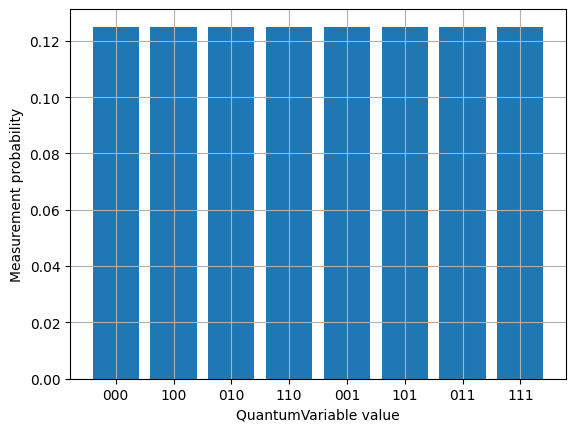

In [17]:
qv = QuantumVariable(3)
h(qv)
qv.get_measurement(plot=True);

In [18]:
qv.qs.statevector()

sqrt(2)*(|000> + |001> + |010> + |011> + |100> + |101> + |110> + |111>)/4

### The exponential wall

A state of $n$ qubits is described by one amplitude for every possible bitstring, that is, by $2^n$ numbers. Each additional qubit **doubles** the amount of information a classical computer needs to keep track of. Let's estimate how much memory a simulator needs to store a statevector (16 bytes per complex amplitude):

In [19]:
def human_readable(num_bytes):
    for unit in ["B", "KB", "MB", "GB", "TB", "PB", "EB"]:
        if num_bytes < 1000:
            return f"{num_bytes:.0f} {unit}"
        num_bytes /= 1000
    return f"{num_bytes:.0f} ZB"

for n in [10, 20, 30, 40, 50, 60]:
    print(f"{n:3d} qubits: {2**n:.1e} amplitudes -> {human_readable(16 * 2**n)}")

 10 qubits: 1.0e+03 amplitudes -> 16 KB
 20 qubits: 1.0e+06 amplitudes -> 17 MB
 30 qubits: 1.1e+09 amplitudes -> 17 GB
 40 qubits: 1.1e+12 amplitudes -> 18 TB
 50 qubits: 1.1e+15 amplitudes -> 18 PB
 60 qubits: 1.2e+18 amplitudes -> 18 EB


Around 50 qubits, storing the statevector exceeds the memory of the world's largest supercomputers. A quantum computer, in contrast, simply *has* this state. This is one hint at why quantum computers might be so powerful.

There is an important catch, though: when you measure $n$ qubits, you get back just $n$ bits, a single random outcome. All those amplitudes are not directly accessible. A quantum computer is not a machine that "tries all answers in parallel and hands you the best one". Useful algorithms need clever interference to concentrate the amplitude on the answers we care about.

## 4. Entanglement

### The CNOT gate

To make qubits interact, we need gates that act on more than one qubit. The most important one is the **controlled NOT** (CNOT, called `cx` in Qrisp). It has a *control* qubit and a *target* qubit, and it flips the target if and only if the control is 1. Let's check its truth table:

In [20]:
from qrisp import cx

for control_bit in [0, 1]:
    for target_bit in [0, 1]:
        q = QuantumVariable(2)
        if control_bit:
            x(q[0])
        if target_bit:
            x(q[1])
        cx(q[0], q[1])  # q[0] is the control, q[1] is the target
        result = list(q.get_measurement())[0]
        print(f"input {control_bit}{target_bit}  ->  output {result}")

input 00  ->  output 00
input 01  ->  output 01
input 10  ->  output 11
input 11  ->  output 10


With definite inputs, the CNOT behaves like a perfectly ordinary classical gate. Things get interesting once the control qubit is in superposition.

### Creating a Bell state

Let's put the first qubit into superposition with H and then apply a CNOT:

In [21]:
bell = QuantumVariable(2, name="bell")
h(bell[0])
cx(bell[0], bell[1])

print(bell)
print(bell.qs)

{'00': 0.5, '11': 0.5}
QuantumCircuit:
---------------
        ┌───┐     
bell.0: ┤ H ├──■──
        └───┘┌─┴─┐
bell.1: ─────┤ X ├
             └───┘
Live QuantumVariables:
----------------------
QuantumVariable bell


In [22]:
bell.qs.statevector()

sqrt(2)*(|00> + |11>)/2

The result is the state

$$|\Phi^+\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right),$$

one of the four famous **Bell states**. Look closely at the measurement results: each qubit on its own is completely random, 0 or 1 with equal probability. Yet the two qubits **always agree**. We never see `'01'` or `'10'`.

This state cannot be described by giving each qubit its own state. If we try to write it as (state of qubit 0) times (state of qubit 1),

$$(a|0\rangle + b|1\rangle)(c|0\rangle + d|1\rangle) = ac|00\rangle + ad|01\rangle + bc|10\rangle + bd|11\rangle,$$

we would need $ad = 0$ and $bc = 0$ (no `01` or `10`), while $ac$ and $bd$ must both be nonzero. That's impossible. States like this are called **entangled**: the qubits form a single whole, and only the combined system has a well-defined state.

### Alice and Bob

To emphasize that entangled qubits can belong to different parties, let's give the two qubits to the traditional protagonists of quantum information, Alice and Bob, as two separate QuantumVariables. We can measure both together using `multi_measurement`:

In [23]:
from qrisp import multi_measurement

alice = QuantumVariable(1, name="alice")
bob = QuantumVariable(1, name="bob")

h(alice)
cx(alice, bob)  # works on whole variables, since both hold exactly one qubit

print(multi_measurement([alice, bob]))

{('0', '0'): 0.5, ('1', '1'): 0.5}


Imagine Alice and Bob now travel to opposite ends of the galaxy. When Alice measures her qubit and finds 0, she instantly knows that Bob will also find 0. Does this let Alice send messages faster than light? No. Bob's qubit on its own looks perfectly random, no matter what Alice does:

In [24]:
print(bob)

{'0': 0.5, '1': 0.5}


Only when Alice and Bob compare their results (which requires ordinary, light-speed-limited communication) do the correlations show up.

### Entanglement is more than classical correlation

A skeptic might object: *"This is just like putting one glove in each of two boxes. Open one box, find a left glove, and you know the other is a right glove. Nothing spooky about it."*

In the glove picture, the pair is secretly either `00` or `11` from the start, we just don't know which. Let's test that against the real thing. We'll measure in a different way, applying an H gate to each qubit right before measuring. First, the classical "glove" version: with probability 1/2 we prepare `00`, otherwise `11`.

In [25]:
glove_results = {}
for prepared in ["00", "11"]:  # a coin decides which pair we prepare
    pair = QuantumVariable(2)
    pair[:] = prepared  # encode the bitstring
    h(pair)
    for outcome, prob in pair.get_measurement().items():
        glove_results[outcome] = glove_results.get(outcome, 0) + 0.5 * prob

print("Classical 'gloves':", glove_results)

Classical 'gloves': {'00': 0.25, '10': 0.25, '01': 0.25, '11': 0.25}


The correlation is completely gone: all four outcomes are equally likely. Now the entangled Bell pair:

In [26]:
alice = QuantumVariable(1, name="alice")
bob = QuantumVariable(1, name="bob")
h(alice)
cx(alice, bob)

# measure in a different basis
h(alice)
h(bob)

print("Entangled pair:", multi_measurement([alice, bob]))

Entangled pair: {('0', '0'): 0.5, ('1', '1'): 0.5}


The entangled qubits are **still perfectly correlated**! Their correlation doesn't depend on which basis we measure in, something no pair of pre-arranged gloves can reproduce. Turning this observation into a rigorous experimental test is the content of *Bell's theorem*, and the experiments confirming it were awarded the 2022 Nobel Prize in Physics.

### The four Bell states

Starting from $|\Phi^+\rangle$, we can reach the other three Bell states with a single X and/or Z gate:

| Name | State | Extra gates |
|---|---|---|
| $\lvert\Phi^+\rangle$ | $\frac{1}{\sqrt{2}}(\lvert 00\rangle + \lvert 11\rangle)$ | none |
| $\lvert\Phi^-\rangle$ | $\frac{1}{\sqrt{2}}(\lvert 00\rangle - \lvert 11\rangle)$ | Z on qubit 0 |
| $\lvert\Psi^+\rangle$ | $\frac{1}{\sqrt{2}}(\lvert 01\rangle + \lvert 10\rangle)$ | X on qubit 1 |
| $\lvert\Psi^-\rangle$ | $\frac{1}{\sqrt{2}}(\lvert 01\rangle - \lvert 10\rangle)$ | X on qubit 1, then Z on qubit 0 |

Let's write a small function that prepares any of them:

In [27]:
from IPython.display import display

def bell_state(name):
    q = QuantumVariable(2)
    h(q[0])
    cx(q[0], q[1])
    if name in ["Psi+", "Psi-"]:
        x(q[1])
    if name in ["Phi-", "Psi-"]:
        z(q[0])
    return q

for name in ["Phi+", "Phi-", "Psi+", "Psi-"]:
    print(name)
    display(bell_state(name).qs.statevector())

Phi+


sqrt(2)*(|00> + |11>)/2

Phi-


sqrt(2)*(|00> - |11>)/2

Psi+


sqrt(2)*(|01> + |10>)/2

Psi-


sqrt(2)*(|01> - |10>)/2

The idea extends to any number of qubits. Chaining CNOTs produces the **GHZ state**, in which all qubits are either 0 together or 1 together:

In [28]:
ghz = QuantumVariable(5)
h(ghz[0])
for i in range(4):
    cx(ghz[i], ghz[i + 1])

ghz.qs.statevector()

sqrt(2)*(|00000> + |11111>)/2

> **Try it yourself:** Use `bell_state("Psi-")` and apply H to both qubits before measuring. Are the results correlated or anti-correlated?

### Application: quantum teleportation

Entanglement is not just a curiosity, it's a resource. Here is a famous example. Alice holds a qubit in some state $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ and wants to send it to Bob. She faces two problems:

- She can't simply measure it and tell Bob the result, because a measurement only yields 0 or 1 and destroys the amplitudes $\alpha$ and $\beta$.
- She can't make a copy of it to examine at leisure either. A fundamental result called the **no-cloning theorem** says that unknown quantum states cannot be copied.

But if Alice and Bob share a Bell pair, Alice can **teleport** the state:

1. Alice entangles her message qubit with her half of the Bell pair (a CNOT followed by an H).
2. She measures her two qubits and sends the two resulting classical bits to Bob (by phone, for example).
3. Depending on these bits, Bob applies an X and/or a Z gate to his qubit, which then holds exactly $|\psi\rangle$.

On real hardware, step 2 involves measuring in the middle of the computation and choosing gates based on the result. A standard trick, the *principle of deferred measurement*, says we get the same final result for Bob by replacing "measure, then apply X/Z depending on the result" with controlled gates (`cx` and `cz`). That's what we'll do here:

In [29]:
from qrisp import cz

theta = 1.2  # this angle defines the state Alice wants to send

message = QuantumVariable(1, name="message")
alice = QuantumVariable(1, name="alice")
bob = QuantumVariable(1, name="bob")

# Prepare the message |psi> = cos(theta/2)|0> + sin(theta/2)|1>
ry(theta, message)

# Alice and Bob share a Bell pair
h(alice)
cx(alice, bob)

# Step 1: Alice entangles the message with her half of the pair
cx(message, alice)
h(message)

# Steps 2 + 3: Bob's corrections (as controlled gates, via deferred measurement)
cx(alice, bob)
cz(message, bob)

print(message.qs)

QuantumCircuit:
---------------
           ┌─────────┐          ┌───┐   
message.0: ┤ Ry(1.2) ├───────■──┤ H ├─■─
           └──┬───┬──┘     ┌─┴─┐└───┘ │ 
  alice.0: ───┤ H ├─────■──┤ X ├──■───┼─
              └───┘   ┌─┴─┐└───┘┌─┴─┐ │ 
    bob.0: ───────────┤ X ├─────┤ X ├─■─
                      └───┘     └───┘   
Live QuantumVariables:
----------------------
QuantumVariable message
QuantumVariable alice
QuantumVariable bob


Let's check whether Bob's qubit now has the message's measurement statistics, $\cos^2(\theta/2)$ and $\sin^2(\theta/2)$:

In [30]:
bob_result = bob.get_measurement()
print("Bob measures:", bob_result)
print(f"Expected:      P(0) = {np.cos(theta / 2)**2:.5f},  P(1) = {np.sin(theta / 2)**2:.5f}")

Bob measures: {'0': 0.68118, '1': 0.31882}
Expected:      P(0) = 0.68118,  P(1) = 0.31882


Matching probabilities are a good sign, but a state is more than its probabilities (remember phases!). For a stronger test, Bob undoes Alice's preparation by rotating his qubit back by $-\theta$. If he really holds $|\psi\rangle$, he must end up in $|0\rangle$ with certainty:

In [31]:
ry(-theta, bob)
print(bob)

{'0': 1.0}


The state made it to Bob intact. Note that Alice's message qubit no longer holds $|\psi\rangle$, so no copy was made, and Bob needs Alice's two classical bits to fix up his qubit, so no information traveled faster than light. Both fundamental rules are respected.

> **Note:** Qrisp also supports *genuine* mid-circuit measurements with real-time classical control through its Jasp compilation pipeline. You'll learn about it in [How to think in Jasp](Jasp.ipynb).

## 5. Thinking in variables, not qubits: the Qrisp way

So far we've been placing gates on individual qubits. That's a great way to learn the basics, but it's a bit like programming a classical computer in assembly language. Real algorithms work with numbers, comparisons and functions. Qrisp provides **quantum types** that let you express exactly that.

### QuantumFloat: numbers in superposition

A [QuantumFloat](../../reference/Quantum%20Types/QuantumFloat.rst) represents a number. With 3 qubits it can hold the integers 0 to 7, stored in binary. You can assign a value using the slicing operator, and Qrisp automatically translates measurement results back into numbers:

In [32]:
from qrisp import QuantumFloat

a = QuantumFloat(3)
a[:] = 5
print(a)

{5: 1.0}


Apply H to every qubit and the QuantumFloat holds a superposition of all eight numbers at once. And now for something remarkable: we can do arithmetic on this superposition, using ordinary Python syntax.

In [33]:
a = QuantumFloat(3)
h(a)
print(a)

b = a * a
print(multi_measurement([a, b]))

{0: 0.125, 1: 0.125, 2: 0.125, 3: 0.125, 4: 0.125, 5: 0.125, 6: 0.125, 7: 0.125}
{(0, 0): 0.125, (1, 1): 0.125, (2, 4): 0.125, (3, 9): 0.125, (4, 16): 0.125, (5, 25): 0.125, (6, 36): 0.125, (7, 49): 0.125}


A single multiplication circuit computed the square of all eight numbers simultaneously. This is often called **quantum parallelism**. Notice also that `a` and `b` are now **entangled**: if we measure `a` and find 3, then `b` is guaranteed to be 9. Computing a function of a superposition naturally creates entanglement between the input and the output.

But remember the catch from Section 3: a measurement only gives us *one* random pair $(x, x^2)$. That's no better than picking a random number classically and squaring it. To get a real advantage, quantum algorithms combine parallelism with interference, as we'll see in the next section.

### QuantumBool: conditions in superposition

Comparisons work too. They produce a [QuantumBool](../../reference/Quantum%20Types/QuantumBool.rst), which is True and False at the same time, entangled with the number it describes:

In [34]:
c = QuantumFloat(3)
h(c)
is_small = c < 3
print(multi_measurement([c, is_small]))

{(0, True): 0.125, (1, True): 0.125, (2, True): 0.125, (3, False): 0.125, (4, False): 0.125, (5, False): 0.125, (6, False): 0.125, (7, False): 0.125}


### Garbage and uncomputation

Computing intermediate results like `b` or `is_small` leaves behind extra qubits that are entangled with our data. That turns out to be a serious problem. Let's repeat our interference experiment from Section 2 (H followed by H), but this time we copy the qubit's value into a helper qubit in between, just like a leftover intermediate result would:

In [35]:
q = QuantumVariable(1, name="q")
h(q)
h(q)
print("Without garbage:", q.get_measurement())

q = QuantumVariable(1, name="q")
garbage = QuantumVariable(1, name="garbage")
h(q)
cx(q, garbage)  # a leftover intermediate result, entangled with q
h(q)
print("With garbage:   ", q.get_measurement())

Without garbage: {'0': 1.0}
With garbage:    {'0': 0.5, '1': 0.5}


The interference is gone! Because the garbage qubit "remembers" which path `q` took, the two paths can no longer cancel each other. This is why quantum programs must clean up their intermediate results by running the computation that created them in reverse, a process called **uncomputation**. Doing this by hand is tedious and error-prone.

Qrisp does it for you. A function decorated with `@auto_uncompute` automatically uncomputes all temporary values it creates (see [Uncomputation](../../reference/Core/Uncomputation.rst) for details). Here is a function that flips the sign of every number smaller than 3:

In [36]:
from qrisp import auto_uncompute

@auto_uncompute
def mark_small_numbers(x):
    z(x < 3)  # compute the condition, flip the phase where it's True, clean up

c = QuantumFloat(3)
h(c)
mark_small_numbers(c)
c.qs.statevector()

sqrt(2)*(-|0> - |1> - |2> + |3> + |4> + |5> + |6> + |7>)/4

The numbers 0, 1 and 2 now carry a minus sign, the temporary QuantumBool has been cleanly removed, and no garbage is left behind.

A function like this, which flips the phase of exactly those inputs that satisfy some condition, is called a **phase oracle**. Written in Qrisp, an oracle reads almost like the condition it checks. This is the central ingredient of the algorithms we're about to explore.

## 6. Your first quantum algorithms

Almost every quantum algorithm follows the same four-step recipe. You have already seen each ingredient:

1. **Superposition:** create a superposition of all possible inputs (H gates).
2. **Oracle:** mark the inputs we care about by flipping their phase (Z on a condition).
3. **Interference:** make the marked phases interfere so the answer's amplitude grows (H gates or a "diffuser").
4. **Measurement:** read out the answer.

### The Deutsch–Jozsa algorithm

**The problem:** Someone gives you a black-box function $f$ that takes a number $x$ between 0 and $2^n - 1$ and outputs 0 or 1. You are promised that $f$ is either **constant** (the same output for every $x$) or **balanced** (0 for exactly half of the inputs and 1 for the other half). Your task is to find out which.

**Classically**, in the worst case, you have to evaluate $f$ on more than half of all inputs, $2^{n-1} + 1$ evaluations, before you can be sure. **A quantum computer needs a single evaluation.**

We give the quantum computer access to $f$ as a phase oracle, which multiplies the amplitude of $|x\rangle$ by $(-1)^{f(x)}$. With Qrisp, writing such oracles is easy. Here are two constant and two balanced functions on 3-qubit numbers (0 to 7):

In [37]:
def constant_zero(x):
    pass  # f(x) = 0 for every x: no amplitude gets flipped

@auto_uncompute
def constant_one(x):
    z(x >= 0)  # f(x) = 1 for every x: every amplitude gets flipped

@auto_uncompute
def balanced_threshold(x):
    z(x >= 4)  # f(x) = 1 for x in {4, 5, 6, 7}

def balanced_odd(x):
    z(x[0])  # x[0] is the least significant bit, so f(x) = 1 for odd x

The algorithm itself is the four-step recipe in its purest form:

In [38]:
def deutsch_jozsa(oracle, n=3):
    x = QuantumFloat(n)
    h(x)        # 1. superposition of all inputs
    oracle(x)   # 2. a single oracle query
    h(x)        # 3. interference
    return x.get_measurement()  # 4. measurement

oracles = {
    "constant_zero": constant_zero,
    "constant_one": constant_one,
    "balanced_threshold": balanced_threshold,
    "balanced_odd": balanced_odd,
}

for name, oracle in oracles.items():
    result = deutsch_jozsa(oracle)
    verdict = "constant" if result.get(0, 0) > 0.99 else "balanced"
    print(f"{name:20s} measured {str(result):10s} -> {verdict}")

constant_zero        measured {0: 1.0}   -> constant
constant_one         measured {0: 1.0}   -> constant
balanced_threshold   measured {4: 1.0}   -> balanced
balanced_odd         measured {1: 1.0}   -> balanced


For the constant functions we always measure 0, for the balanced ones we *never* do. One query, and we know the answer with certainty.

**Why does it work?** After the final layer of H gates, the amplitude of the outcome 0 turns out to be the *average* of all the signs $(-1)^{f(x)}$. If $f$ is constant, all signs are equal and the average is $\pm 1$: we measure 0 with certainty. If $f$ is balanced, exactly half of the signs are $+1$ and half are $-1$. They cancel perfectly, and the outcome 0 never appears. Interference at work!

### The Bernstein–Vazirani algorithm

**The problem:** This time the black box hides a secret bitstring $s$. On input $x$ (also a bitstring), it returns the parity of the bits that $x$ and $s$ have in common, $f(x) = s_0 x_0 \oplus s_1 x_1 \oplus \dots \oplus s_{n-1} x_{n-1}$. Your task is to find $s$.

**Classically**, each query reveals one bit of information, so you need $n$ queries (for example, query `1000...`, `0100...` and so on to read off one bit at a time). **Quantum mechanically, one query reveals the whole string.**

The phase oracle for this function has a very simple structure: $(-1)^{f(x)}$ is a product of a $-1$ for every position where both $s_i$ and $x_i$ are 1. That's just a Z gate on every qubit where $s_i = 1$:

In [39]:
def bernstein_vazirani_oracle(x, secret):
    for i, bit in enumerate(secret):
        if bit == "1":
            z(x[i])

def bernstein_vazirani(secret):
    x = QuantumVariable(len(secret))
    h(x)                                  # 1. superposition
    bernstein_vazirani_oracle(x, secret)  # 2. one oracle query
    h(x)                                  # 3. interference
    return x.get_measurement()            # 4. measurement

print(bernstein_vazirani("101101"))

{'101101': 1.0}


The secret string pops out with 100% probability after a single query. You actually already know why: on every qubit where $s_i = 1$ the circuit performs H, then Z, then H, which we found in Section 2 to be the same as an X gate. Every other qubit sees H followed by H, which does nothing. So the circuit simply writes $s$ into the register!

Admittedly, Deutsch–Jozsa and Bernstein–Vazirani solve rather artificial problems. Their importance is historical and conceptual: they were among the first proofs that quantum computers can beat classical ones, and their ideas paved the way to Simon's algorithm and, eventually, Shor's famous factoring algorithm.

### Grover's search algorithm

Now for a truly versatile algorithm. **The problem:** among $N$ possibilities, find the one that satisfies a given condition, with no structure to exploit. Think of finding a name in a phone book given only the phone number. **Classically**, you have to check the entries one by one, about $N/2$ checks on average. **Grover's algorithm** needs only about $\frac{\pi}{4}\sqrt{N}$ oracle queries. For a million entries, that's roughly 785 queries instead of 500,000.

Let's search for the number 11 among the 16 numbers a 4-qubit QuantumFloat can hold. The oracle is, once again, a condition:

In [40]:
@auto_uncompute
def oracle(x):
    z(x == 11)

The second ingredient is the **diffuser**, which Qrisp provides out of the box (see [Grover tools](../../reference/Primitives/Grover%20tools.rst)). It performs an "inversion about the mean": every amplitude is reflected around the average amplitude, $\text{amplitude} \to 2\cdot\text{mean} - \text{amplitude}$.

Let's follow the numbers through one Grover iteration (oracle followed by diffuser):

- **Start:** all 16 amplitudes are $\frac{1}{4} = 0.25$. Each outcome has probability $0.0625$.
- **Oracle:** the amplitude of 11 flips to $-0.25$. The mean drops to $\frac{15 \cdot 0.25 - 0.25}{16} = 0.21875$.
- **Diffuser:** the 15 unmarked amplitudes become $2 \cdot 0.21875 - 0.25 = 0.1875$, while the marked one becomes $2 \cdot 0.21875 + 0.25 = 0.6875$.

The probability of finding 11 jumped from $0.0625$ to $0.6875^2 \approx 0.473$. Let's verify this with Qrisp:

In [41]:
from qrisp.grover import diffuser

x = QuantumFloat(4)
h(x)
oracle(x)
diffuser(x)
print(x)

{11: 0.47263164210147396, 0: 0.035157890526568404, 1: 0.035157890526568404, 2: 0.035157890526568404, 3: 0.035157890526568404, 4: 0.035157890526568404, 5: 0.035157890526568404, 6: 0.035157890526568404, 7: 0.035157890526568404, 8: 0.035157890526568404, 9: 0.035157890526568404, 10: 0.035157890526568404, 12: 0.035157890526568404, 13: 0.035157890526568404, 14: 0.035157890526568404, 15: 0.035157890526568404}


Exactly as predicted. Each further iteration rotates more amplitude onto the solution. Let's see how the success probability evolves with the number of iterations:

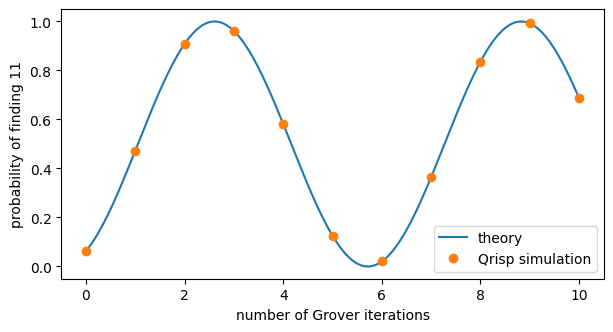

In [42]:
def grover_success_probability(iterations, target=11, n=4):
    x = QuantumFloat(n)
    h(x)
    for _ in range(iterations):
        oracle(x)
        diffuser(x)
    return x.get_measurement().get(target, 0)

iterations = list(range(11))
probabilities = [grover_success_probability(k) for k in iterations]

# Theory: P(k) = sin^2((2k+1) * arcsin(1/sqrt(N)))
N = 16
fine = np.linspace(0, 10, 200)
theory = np.sin((2 * fine + 1) * np.arcsin(1 / np.sqrt(N))) ** 2

plt.figure(figsize=(7, 3.5))
plt.plot(fine, theory, label="theory")
plt.plot(iterations, probabilities, "o", label="Qrisp simulation")
plt.xlabel("number of Grover iterations")
plt.ylabel("probability of finding 11")
plt.legend()
plt.show()

The success probability peaks after 3 iterations (close to $\frac{\pi}{4}\sqrt{16} \approx 3.1$) and then **decreases** again. Unlike a classical search, doing more work is not always better: too many iterations rotate the state past the solution. The probability oscillates and comes back around at 9 iterations, but that costs three times as many oracle queries for a similar result, so we always aim for the first peak. Let's run the search with the optimal number of iterations:

In [43]:
optimal = int(np.pi / 4 * np.sqrt(N))
print("Optimal number of iterations:", optimal)

x = QuantumFloat(4)
h(x)
for _ in range(optimal):
    oracle(x)
    diffuser(x)

result = x.get_measurement()
print(f"P(11) = {result[11]:.4f}")

Optimal number of iterations: 3
P(11) = 0.9613


With just 3 queries, we find the marked number with over 96% probability.

The speedup of Grover's algorithm is "only" quadratic, but it applies to a huge range of problems: anything where you can efficiently *check* a candidate solution. Since Qrisp oracles are written as high-level conditions, you can search for solutions of equations, valid routes or Sudoku fillings without ever thinking about individual gates. You'll see exactly that in the [next tutorial](tutorial.ipynb), where Grover's algorithm solves a quadratic equation.

> **Try it yourself:** Change the oracle to search for a different number, or for two numbers at once using `z((x == 3) | (x == 11))`. How does the optimal number of iterations change? What happens with a 6-qubit QuantumFloat?

## 7. From simulator to real quantum computers

Everything in this tutorial ran on a simulator, which works well up to a few dozen qubits. Real quantum computers exist today, but they are still small and **noisy**: qubits are fragile, and every gate introduces a small error. Building large, error-corrected (fault-tolerant) quantum computers is one of the great engineering challenges of our time.

Since Qrisp compiles your high-level code into circuits, the same code can run on real hardware by passing a `backend` to `get_measurement`. Qrisp supports devices from IBM ([QiskitRuntimeBackend](../../reference/Backend%20Interface/Hardware%20Backends/QiskitRuntimeBackend.rst)), IQM ([IQMBackend](../../reference/Backend%20Interface/Hardware%20Backends/IQMBackend.rst)) and AQT ([AQTBackend](../../reference/Backend%20Interface/Hardware%20Backends/AQTBackend.rst)). For example, to measure a Bell state on an IQM machine:

In [44]:
# Make sure to install qrisp with the IQM interface: pip install qrisp[iqm]
# from qrisp.interface import IQMBackend
# iqm_garnet = IQMBackend(api_token="IQM_RESONANCE_API_TOKEN", device_instance="garnet")
# print(bell.get_measurement(backend=iqm_garnet))

On real hardware, you would see mostly `'00'` and `'11'`, plus a small fraction of `'01'` and `'10'` caused by noise.

## Summary

Congratulations, you've taken your first steps into quantum computing! Here's what you've learned and how each concept looks in Qrisp:

| Concept | What it means | In Qrisp |
|---|---|---|
| Qubit | The basic unit of quantum information, measured as 0 or 1 | `QuantumVariable(1)` |
| Superposition | A combination $\alpha\lvert 0\rangle + \beta\lvert 1\rangle$ of basis states | `h(qv)`, `ry(theta, qv)` |
| Measurement | Random outcome with probability $\lvert\text{amplitude}\rvert^2$; destroys the superposition | `print(qv)`, `qv.get_measurement(shots=...)` |
| Interference | Amplitudes add up or cancel out | `h(qv); h(qv)` returns to $\lvert 0\rangle$ |
| Phase | The sign of an amplitude, visible only through interference | `z(qv)` |
| Entanglement | Qubits that share a single joint state | `h(a); cx(a, b)` |
| Quantum types | Numbers and booleans in superposition | `QuantumFloat`, `QuantumBool`, `a * a`, `c < 3` |
| Uncomputation | Cleaning up temporary results so interference keeps working | `@auto_uncompute` |
| Phase oracle | Flips the sign of the inputs that satisfy a condition | `z(x == 11)` |

And you've implemented three quantum algorithms, all following the same recipe of superposition, oracle, interference and measurement.

### Where to go next

- [Getting familiar with Qrisp](tutorial.ipynb) dives deeper into QuantumVariables, uses Grover's algorithm to solve a quadratic equation and introduces Quantum Phase Estimation.
- [Factoring integers using Shor's algorithm](Shor.ipynb) shows the algorithm that famously threatens today's cryptography.
- [Solving the Traveling Salesman Problem](TSP.ipynb) and [Solving Sudoku using Quantum Backtracking](Sudoku.ipynb) apply oracle-based search to real-world-style problems.

Happy quantum programming!